Cuando se hace un análisis o simulación de activos los cuales están correlacionados ocurre algo que pasa continuamente, dependiendo del ramo, dependiendo si el activo esta relacionado con un determinado giro, tiene una correlación con los otros activos de la cartera, sin embargo, esta correlación casi siempre termina siendo variable dependiendo del tiempo en el que se análice. Algunas veces activos que estaban cero correlacionados cuando ocurre una crisis o un shock, se mueven casi a la par esto ya que generalmente cualquier crisis afecta a las valuaciones de los activos, algo similar a lo que paso con la PANDEMIA de 2020 o la crisis de 2008. Para ello es necesario analizar el comportamiento de correlaciones en distintos puntos del tiempo, esto es lo que se denomina CORRELACIÓN DINÁMICA, es decir una correlación que se mueve a lo largo del tiempo. 

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Seaborn es una librería de visualización de datos en Python construida sobre Matplotlib. 
# Sirve para crear gráficos estadísticos atractivos, complejos e informativos de forma rápida y con muy pocas líneas de código, 
# integrándose a la perfección con la estructura de datos de Pandas.
import yfinance as yf

# Vamos a utilizar los siguientes activos c: 
tickers = ['AAPL', 'MSFT', 'NVDA', 'SPY']

data = yf.download(tickers, start='2020-01-01', progress=False)['Close']

#Calculamos retornos logaritmos, esto debido a que pasamos de un modelo multiplicativo a aditivo. 
returns = np.log(data / data.shift(1)).dropna()

Primero veamos la matriz de correlación de los activos, pero cuando suponemos que esta es constante, es decir cuando es estática:

In [7]:
corr_matrix = returns.corr()

print(corr_matrix)

Ticker      AAPL      MSFT      NVDA       SPY
Ticker                                        
AAPL    1.000000  0.678923  0.572347  0.776980
MSFT    0.678923  1.000000  0.659876  0.780449
NVDA    0.572347  0.659876  1.000000  0.704371
SPY     0.776980  0.780449  0.704371  1.000000


Podemos observar que en general todas las correlaciones parecen ser mayores a 0.5 para todos lo que implica que muchos de ellos se mueven juntos entre sí, en particular veamos una gráfica más bonita de este hecho.

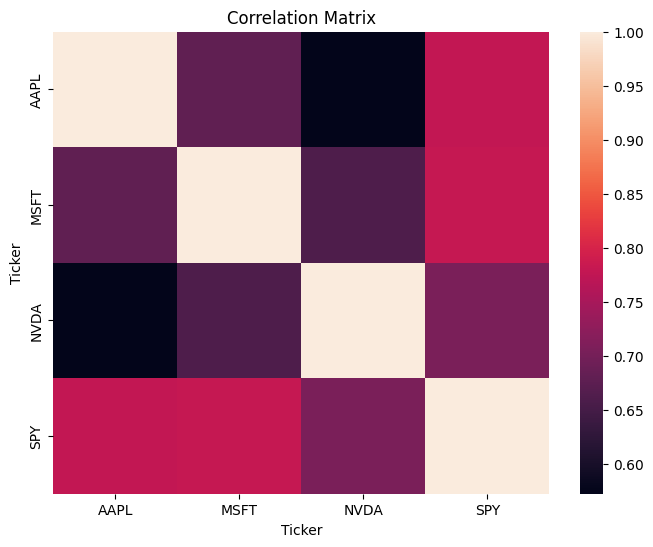

In [11]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

Los activos más correlacionados parecen ser AAPL y MSFT, mientras que los que menos correlación presenta son NVDA y AAPL esto se puede ver en la siguiente gráfica que es como se mueven los precios de los activos:

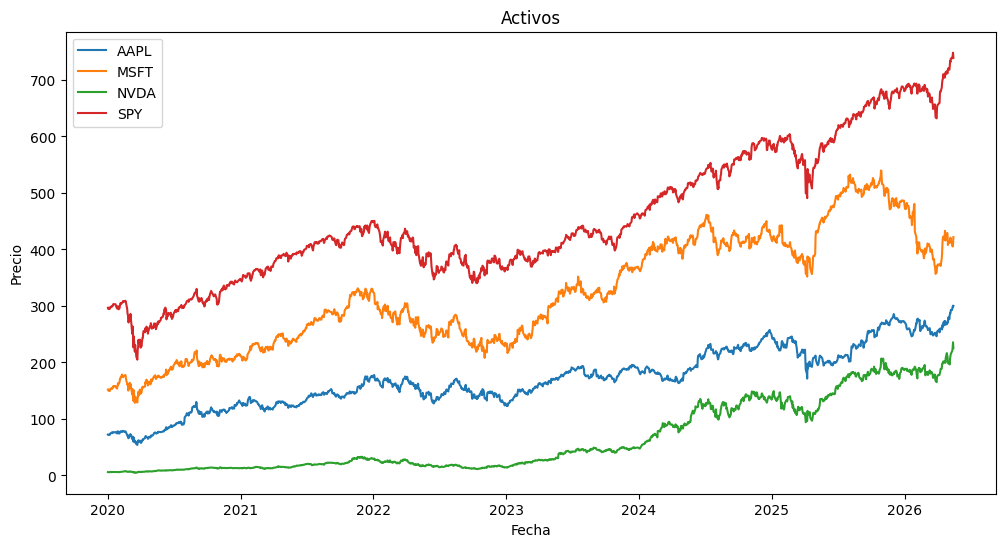

In [14]:
# =========================
# GRÁFICA DE PRECIOS
# =========================

plt.figure(figsize=(12,6))

plt.plot(data.index, data[tickers[0]], label=tickers[0])
plt.plot(data.index, data[tickers[1]], label=tickers[1])
plt.plot(data.index, data[tickers[2]], label=tickers[2])
plt.plot(data.index, data[tickers[3]], label=tickers[3])

plt.title("Activos")
plt.xlabel("Fecha")
plt.ylabel("Precio")

plt.legend()

plt.show()



Ahora debido a que percibimos que a partir de 2024 el comportamiento de los activos es a la alza después de no estar tan correlacionado, procedemos a hacer una correlación dinámica o rodante, en ventanas móviles de 30 días, es decir creamos y calculamos correlación entre dos activos en 30 primeros días, recalculamos al mover toda la ventana un día adelante, volvemos a recalcular y así hasta terminar, primero veamos los activos AAPL y MSFT

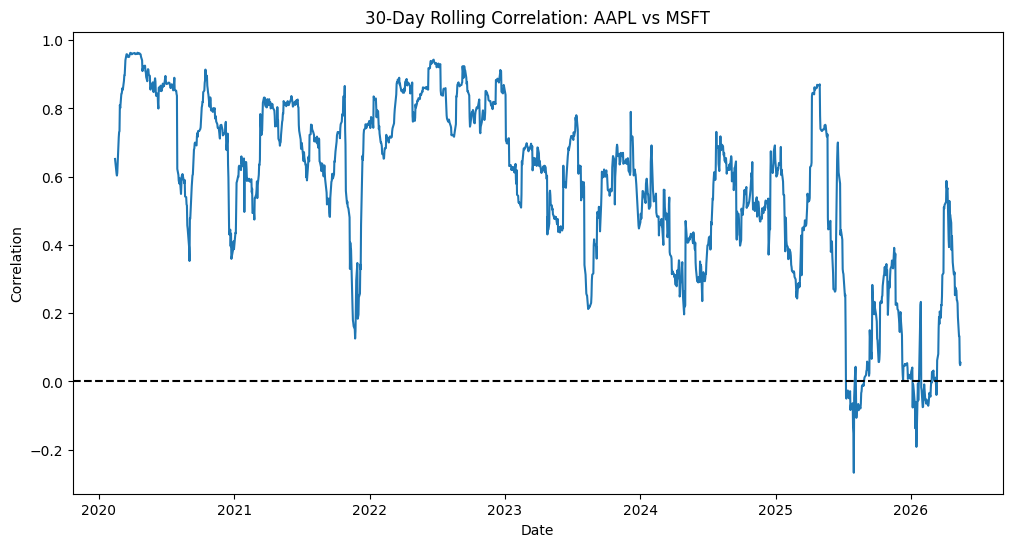

In [16]:
rolling_corr = (
    returns['AAPL']
    .rolling(window=30)
    .corr(returns['MSFT'])
)

plt.figure(figsize=(12,6))

plt.plot(rolling_corr)

plt.title('30-Day Rolling Correlation: AAPL vs MSFT')
plt.ylabel('Correlation')
plt.xlabel('Date')

plt.axhline(0, color='black', linestyle='--')

plt.show()


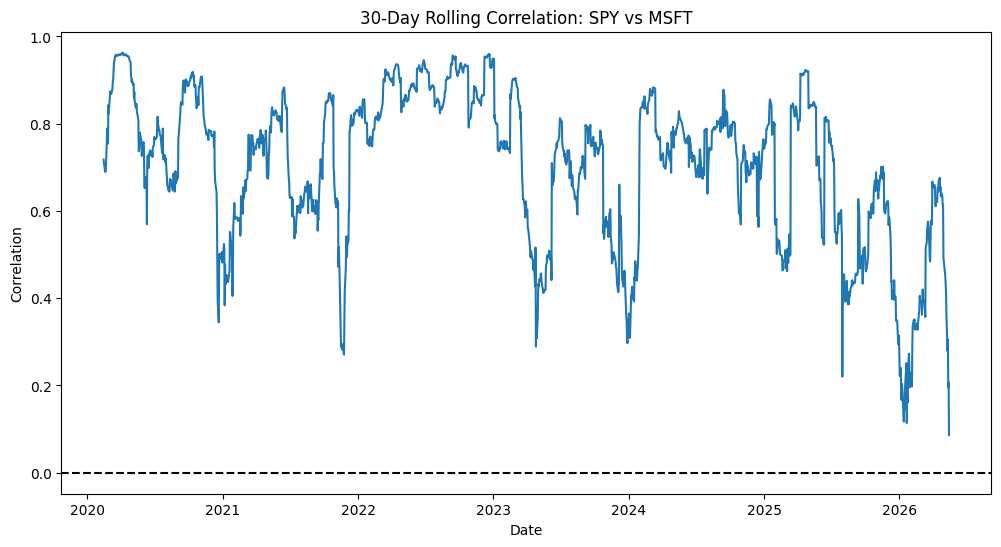

In [17]:
rolling_corr2 = (
    returns['SPY']
    .rolling(window=30)
    .corr(returns['MSFT'])
)

plt.figure(figsize=(12,6))

plt.plot(rolling_corr2)

plt.title('30-Day Rolling Correlation: SPY vs MSFT')
plt.ylabel('Correlation')
plt.xlabel('Date')

plt.axhline(0, color='black', linestyle='--')

plt.show()

En el segundo caso la correlación siempre fue positiva y se notan grandes saltos, waos c:

---

Además también es posible calcular un riesgo rodante o dinámico, es decir, ver como evoluciona a lo largo del tiempo:

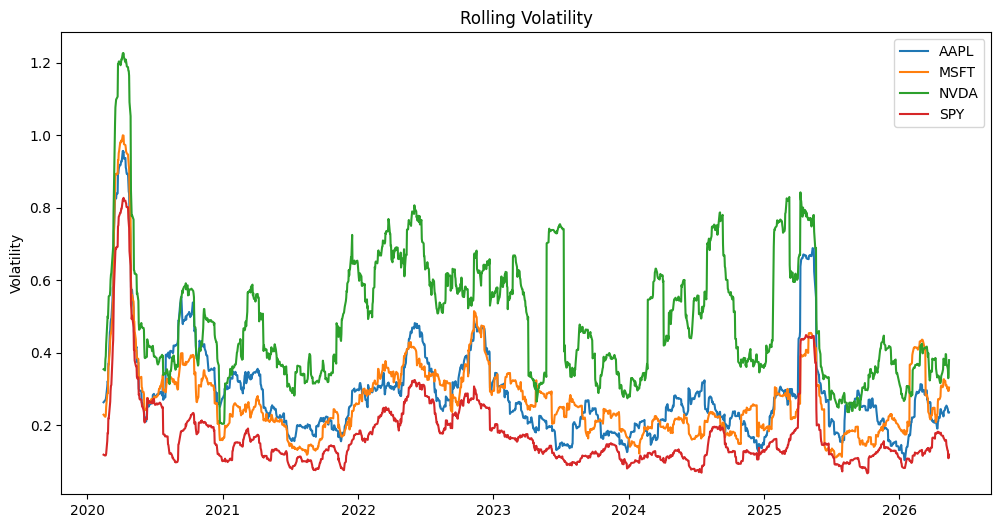

In [25]:
rolling_vol = (
    returns['AAPL']
    .rolling(window=30)
    .std() * np.sqrt(252)  #Recordando que la volatilidad anual es: \sqrt(252)*.std diaria
)
rolling_vol2 = (
    returns['MSFT']
    .rolling(window=30)
    .std() * np.sqrt(252)  #Recordando que la volatilidad anual es: \sqrt(252)*.std diaria
)
rolling_vol3 = (
    returns['NVDA']
    .rolling(window=30)
    .std() * np.sqrt(252)  #Recordando que la volatilidad anual es: \sqrt(252)*.std diaria
)
rolling_vol4 = (
    returns['SPY']
    .rolling(window=30)
    .std() * np.sqrt(252)  #Recordando que la volatilidad anual es: \sqrt(252)*.std diaria
)

plt.figure(figsize=(12,6))

plt.plot(rolling_vol, label = "AAPL")
plt.plot(rolling_vol2, label = "MSFT")
plt.plot(rolling_vol3, label = "NVDA")
plt.plot(rolling_vol4, label = "SPY")

plt.title('Rolling Volatility')
plt.ylabel('Volatility')

plt.legend()

plt.show()

Dónde logramos notar el pico a inicios de 2020 consecuencia del inicio internacional de la Pandemia causada por SARS-COV-19, o a inicios de 2025 causado por la victoria en la contienda electoral de Donald Trump, es súper útil el comportamiento de estas gráficas. 

Por otra parte, alanalizar puntualmente un periodo específico (pandemia), las correlaciones aumentan muchísimo como lo podemos ver a continuación, por ello la necesidad de considerar estos comportamientos, además de qu esto sera la base de lo que se conoce como GARCH.

<Axes: xlabel='Ticker', ylabel='Ticker'>

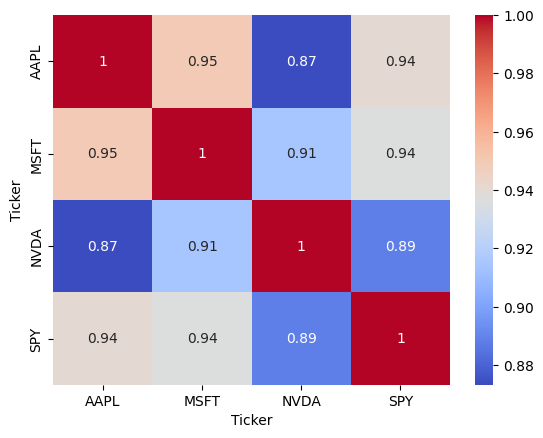

In [26]:
covid_period = returns.loc['2020-03-01':'2020-06-01']

sns.heatmap(covid_period.corr(), annot=True, cmap='coolwarm')